<div style="background:#153c46;color:white;padding:26px;border-radius:8px">
<p style="color:#a4dfd6;letter-spacing:2px">REGRESSION · FEATURE ENGINEERING · MODEL EVALUATION</p>
<h1 style="color:white">Housing Price Prediction</h1>
<p>OLS, Ridge and Lasso on California housing data</p>
<p>Arafat Rahman</p>
</div>

Predict district-level median house values from location, population, housing and income attributes.
Compare the three linear models using the same held-out observations, with all learned preprocessing inside cross-validation.

## 01 · Dataset and Objective

The [official assignment](https://www.datheon.in/training/catalog/machine-learning-and-data-science-internship)
links to [this California housing CSV](https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv).
It has 20,640 rows, eight numeric predictors, one categorical predictor (`ocean_proximity`) and the target `median_house_value` in US dollars.

Each row represents an area, not an individual property. The target is a historical benchmark, not a current market valuation.
The workflow uses an 80/20 split, five-fold training-only cross-validation and fixed feature definitions.
RMSE is the selection metric; MAE and R² provide complementary evaluation.

## 02 · Imports and Reproducibility

Use a fixed seed and a common plotting style. The notebook runs locally or on Kaggle with Internet enabled.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
from importlib.metadata import version
import hashlib
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.validation import check_is_fitted

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('error', category=ConvergenceWarning)
MODEL_COLORS = {'OLS': '#24778a', 'Ridge': '#d18a25', 'Lasso': '#8d6bb3'}
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220,
                     'axes.titleweight': 'bold', 'axes.spines.top': False,
                     'axes.spines.right': False, 'grid.alpha': 0.22})
pd.set_option('display.precision', 3)
cwd = Path.cwd()
if cwd.name == 'Task_02_Housing_Price_Prediction':
    TASK_DIR = cwd
elif (cwd / 'Task_02_Housing_Price_Prediction').is_dir():
    TASK_DIR = cwd / 'Task_02_Housing_Price_Prediction'
elif cwd == Path('/kaggle/working'):
    TASK_DIR = cwd / 'Task_02_Housing_Price_Prediction'
    TASK_DIR.mkdir(exist_ok=True)
else:
    raise RuntimeError('Run from the project root, Task 2 folder or /kaggle/working.')
RESULTS, FIGURES = TASK_DIR / 'results', TASK_DIR / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
def save_figure(fig, filename):
    fig.savefig(FIGURES / filename, bbox_inches='tight', facecolor='white')

display(pd.Series({p: version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','seaborn']},
                  name='Version').to_frame())

,Version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2


## 03 · Load and Validate the Source

Download the required dataset into memory. A failed download stops execution; no alternate dataset is silently substituted.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'
with urlopen(DATA_URL, timeout=60) as response:
    source_bytes = response.read()
source_sha256 = hashlib.sha256(source_bytes).hexdigest()
housing = pd.read_csv(BytesIO(source_bytes))
NUMERIC = ['longitude','latitude','housing_median_age','total_rooms','total_bedrooms',
           'population','households','median_income']
TARGET = 'median_house_value'
EXPECTED_COLUMNS = NUMERIC + [TARGET, 'ocean_proximity']
assert housing.shape == (20640, 10)
assert housing.columns.tolist() == EXPECTED_COLUMNS
assert housing[TARGET].notna().all() and housing[TARGET].gt(0).all()
assert all(pd.api.types.is_numeric_dtype(housing[c]) for c in NUMERIC + [TARGET])
assert not np.isinf(housing[NUMERIC + [TARGET]].to_numpy()).any()
assert set(housing['ocean_proximity']) == {'<1H OCEAN','INLAND','NEAR OCEAN','NEAR BAY','ISLAND'}
assert housing['households'].gt(0).all() and housing['total_rooms'].gt(0).all()
print('Shape:', housing.shape)
print('Source SHA-256:', source_sha256)
display(housing.head())

Shape: (20640, 10)
Source SHA-256: 8a3727f4cf54ac1a327f69b1d5b4db54c5834ea81c6e4efc0d163300022a685e


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.325,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.301,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.257,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.643,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.846,342200.0,NEAR BAY


## 04 · Data Quality

Inspect missingness, types, repeated records and category counts. Missing bedrooms are preserved until fold-specific imputation; no rows are dropped.

In [3]:
quality = pd.DataFrame({'dtype': housing.dtypes.astype(str), 'missing': housing.isna().sum(),
                        'unique': housing.nunique()})
display(quality)
print('Duplicate rows:', int(housing.duplicated().sum()))
assert housing.duplicated().sum() == 0
display(housing['ocean_proximity'].value_counts().rename('rows').to_frame())

,dtype,missing,unique
longitude,float64,0,844
latitude,float64,0,862
housing_median_age,float64,0,52
total_rooms,float64,0,5926
total_bedrooms,float64,207,1923
population,float64,0,3888
households,float64,0,1815
median_income,float64,0,12928
median_house_value,float64,0,3842
ocean_proximity,str,0,5


Duplicate rows: 0


,rows
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


## 05 · Hold Out the Test Set

Reserve 20% before exploratory modelling. All following EDA uses training rows only. The test set is not used to choose features, alpha values or the selected model.

In [4]:
X = housing.drop(columns=TARGET)
y = housing[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
assert len(X_train) == 16512 and len(X_test) == 4128
assert set(X_train.index).isdisjoint(X_test.index)
training = X_train.assign(median_house_value=y_train)
display(pd.DataFrame({'Partition':['Train','Test'], 'Rows':[len(X_train),len(X_test)],
                      'Share':[0.80,0.20]}))
display(training[NUMERIC + [TARGET]].describe().round(2))

,Partition,Rows,Share
0,Train,16512,0.8
1,Test,4128,0.2


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,16512.00,16512.00,16512.00,16512.00,16512.00,16512.00,16512.00,16512.00,16512.00
mean,-119.58,35.64,28.61,2642.00,538.50,1426.45,499.99,3.88,207194.69
std,2.01,2.14,12.60,2174.65,419.01,1137.06,380.97,1.90,115622.63
min,-124.35,32.55,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.81,33.93,18.00,1454.00,296.75,789.00,280.00,2.57,119800.00
50%,-118.51,34.26,29.00,2129.00,437.00,1167.00,410.00,3.55,179850.00
75%,-118.01,37.72,37.00,3160.00,647.00,1726.00,606.00,4.77,265125.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


## 06 · Training Distributions

Check target shape, income and housing counts before fitting. Target values at the upper endpoint are retained and discussed as a limitation.

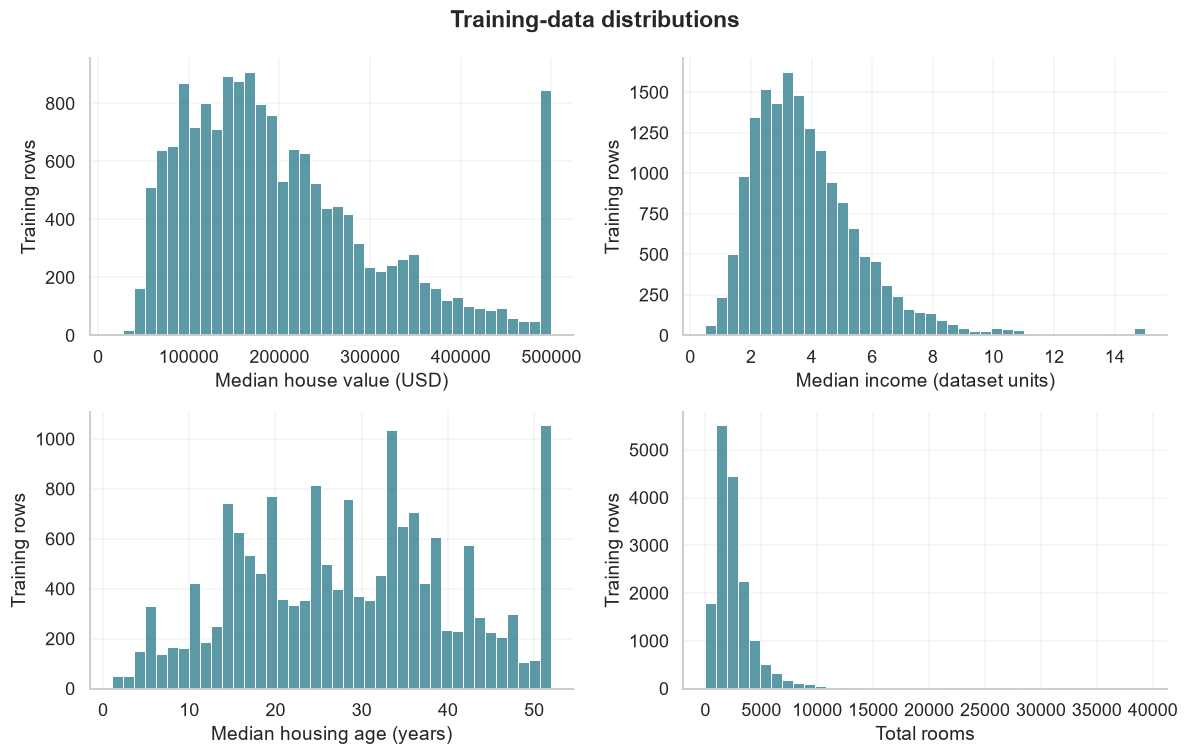

Training target maximum: **$500,001**; **786** training rows share this endpoint.

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feature, label in zip(axes.flat,
        [TARGET, 'median_income', 'housing_median_age', 'total_rooms'],
        ['Median house value (USD)', 'Median income (dataset units)', 'Median housing age (years)', 'Total rooms']):
    sns.histplot(training[feature], bins=40, color='#24778a', ax=ax)
    ax.set(xlabel=label, ylabel='Training rows')
fig.suptitle('Training-data distributions', weight='bold')
fig.tight_layout()
save_figure(fig, 'training_distributions.png')
plt.show()
train_cap = float(y_train.max())
display(Markdown(f'Training target maximum: **${train_cap:,.0f}**; '
                 f'**{int(y_train.eq(train_cap).sum()):,}** training rows share this endpoint.'))

## 07 · Correlation and Multicollinearity

Correlated area totals can make OLS coefficients unstable. The heatmap uses training data; pairwise correlations ignore missing values. Ridge and Lasso provide alternative regularization rather than interpreting coefficients as causal effects.

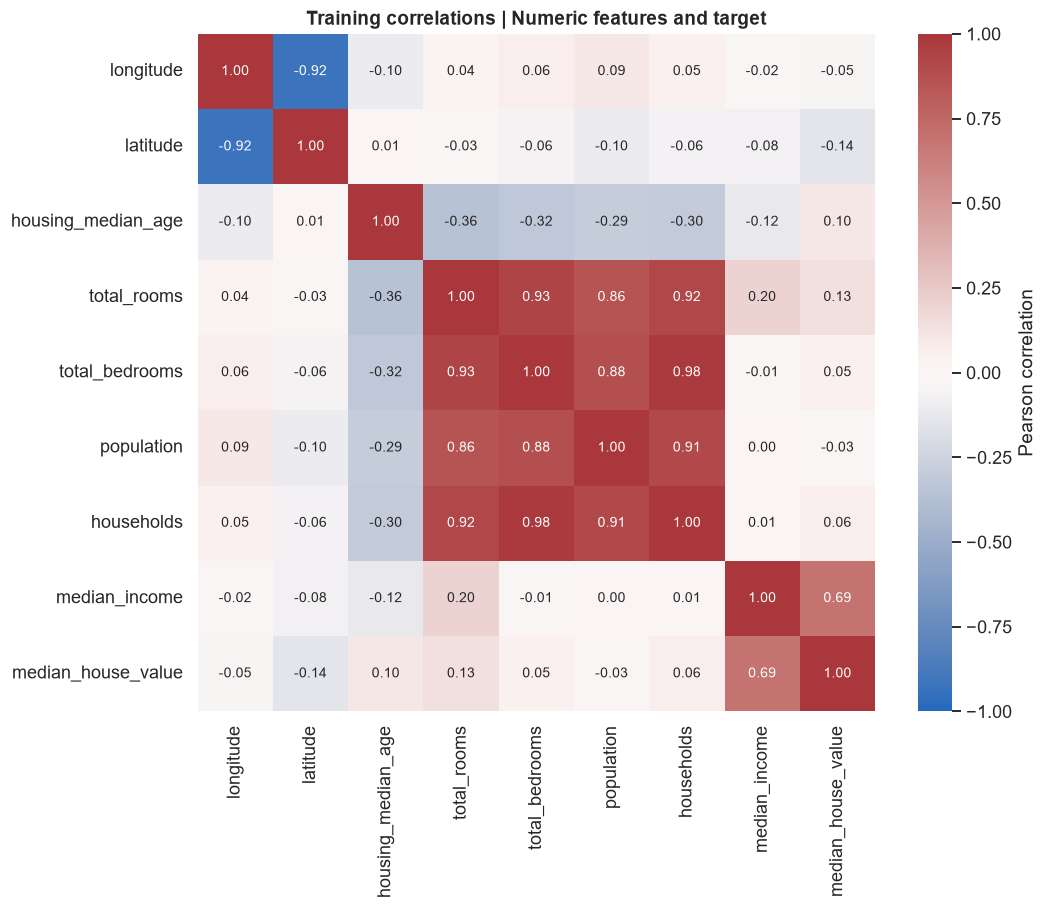

correlation
longitude      latitude             -0.924
total_rooms    total_bedrooms        0.930
               population            0.858
               households            0.920
total_bedrooms population            0.879
               households            0.980
population     households            0.907

In [6]:
correlation = training[NUMERIC + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
            square=True, annot_kws={'fontsize':9}, ax=ax, cbar_kws={'label':'Pearson correlation'})
ax.set_title('Training correlations | Numeric features and target')
save_figure(fig, 'correlation_heatmap.png')
plt.show()
pairs = correlation.loc[NUMERIC, NUMERIC].where(np.triu(np.ones((len(NUMERIC),len(NUMERIC))),k=1).astype(bool)).stack()
display(pairs.loc[pairs.abs() >= 0.80].rename('correlation').to_frame())

## 08 · Feature Engineering

Create three interpretable ratios and two interaction terms, fixed before fitting:

| Feature | Definition |
|:--|:--|
| Rooms per household | Total rooms ÷ households |
| Bedrooms per room | Total bedrooms ÷ total rooms |
| Population per household | Population ÷ households |
| Income × rooms | Median income × rooms per household |
| Income × age | Median income × median housing age |

The transformation learns no population statistics. Missing inputs remain missing and are imputed inside each training fold. Extreme ratios are retained rather than trimmed using test outcomes.

In [7]:
ENGINEERED = ['rooms_per_household','bedrooms_per_room','population_per_household',
              'income_rooms_interaction','income_age_interaction']
def engineer_features(frame):
    frame = frame.copy()
    frame['rooms_per_household'] = frame['total_rooms'] / frame['households'].replace(0, np.nan)
    frame['bedrooms_per_room'] = frame['total_bedrooms'] / frame['total_rooms'].replace(0, np.nan)
    frame['population_per_household'] = frame['population'] / frame['households'].replace(0, np.nan)
    frame['income_rooms_interaction'] = frame['median_income'] * frame['rooms_per_household']
    frame['income_age_interaction'] = frame['median_income'] * frame['housing_median_age']
    return frame.replace([np.inf, -np.inf], np.nan)

display(engineer_features(X_train)[ENGINEERED].describe().round(2))

,rooms_per_household,bedrooms_per_room,population_per_household,income_rooms_interaction,income_age_interaction
count,16512.00,16512.00,16512.00,16512.00,16512.00
mean,5.44,0.21,3.10,22.62,108.10
std,2.39,0.06,11.58,17.55,74.66
min,0.89,0.10,0.69,0.86,2.14
25%,4.45,0.18,2.43,11.71,57.93
50%,5.24,0.20,2.82,18.10,92.17
75%,6.06,0.24,3.28,28.01,140.29
max,141.91,1.00,1243.33,333.34,780.01


## 09 · Leakage-Free Preprocessing

Every estimator contains the same preprocessing pipeline:
numeric median imputation → standardization; categorical most-frequent imputation → one-hot encoding.
Dropping one category avoids redundant dummy columns with an intercept. Unknown categories are handled at prediction time.
Each cross-validation fold fits its own imputer, scaler and encoder using only that fold's training rows.

In [8]:
ALL_NUMERIC = NUMERIC + ENGINEERED
def make_model(estimator):
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())])
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))])
    preprocess = ColumnTransformer([('numeric', numeric, ALL_NUMERIC),
                                    ('category', categorical, ['ocean_proximity'])])
    return Pipeline([('features', FunctionTransformer(engineer_features, validate=False)),
                     ('preprocess', preprocess), ('model', estimator)])

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print('5-fold CV; selection score = negative RMSE (converted to positive USD below).')

5-fold CV; selection score = negative RMSE (converted to positive USD below).


## 10 · OLS Training and Cross-Validation

OLS is the unpenalized comparison. Validation folds match those used for Ridge and Lasso.

In [9]:
ols = make_model(LinearRegression())
ols_fold_rmse = -cross_val_score(ols, X_train, y_train, cv=cv,
                                scoring='neg_root_mean_squared_error', n_jobs=1)
ols.fit(X_train, y_train)
models = {'OLS': ols}
cv_rows = [{'Model':'OLS','Alpha':np.nan,'CV RMSE':ols_fold_rmse.mean(),
            'CV RMSE std':ols_fold_rmse.std()}]
grid_rows = []
display(pd.Series(ols_fold_rmse, index=range(1,6), name='Validation RMSE (USD)').to_frame())

,Validation RMSE (USD)
1,68679.022
2,67360.149
3,64947.020
4,68954.882
5,68435.326


## 11 · Ridge and Lasso Search

Search predefined alpha grids using training-only five-fold CV. Alpha scales are not directly comparable between Ridge and Lasso because their objectives scale penalties differently. Refitting uses all training rows, never the test rows.

In [10]:
specifications = {
    'Ridge': (Ridge(), [0.01,0.1,1,10,100,1000,10000]),
    'Lasso': (Lasso(max_iter=50000, tol=1e-4, random_state=SEED), [0.1,1,10,100,1000,10000])
}
searches = {}
for name, (estimator, alphas) in specifications.items():
    search = GridSearchCV(make_model(estimator), {'model__alpha':alphas},
                           scoring='neg_root_mean_squared_error', cv=cv,
                           n_jobs=1, refit=True, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    models[name] = search.best_estimator_
    best_index = search.best_index_
    cv_rows.append({'Model':name, 'Alpha':search.best_params_['model__alpha'],
                    'CV RMSE':-search.best_score_,
                    'CV RMSE std':search.cv_results_['std_test_score'][best_index]})
    for i, alpha in enumerate(alphas):
        grid_rows.append({'Model':name, 'Alpha':alpha,
                          'CV RMSE':-search.cv_results_['mean_test_score'][i],
                          'CV RMSE std':search.cv_results_['std_test_score'][i]})
cv_summary = pd.DataFrame(cv_rows).set_index('Model')
grid_results = pd.DataFrame(grid_rows)
grid_results.to_csv(RESULTS / 'alpha_search.csv', index=False)
selected_name = cv_summary['CV RMSE'].idxmin()
display(cv_summary.round(2))
display(Markdown(f'**Selected by training CV: {selected_name}.** The held-out set is evaluated next.'))

,Alpha,CV RMSE,CV RMSE std
Model,,,
OLS,NaN,67675.28,1467.33
Ridge,10.0,67663.06,1456.13
Lasso,100.0,67660.87,1439.11


**Selected by training CV: Lasso.** The held-out set is evaluated next.

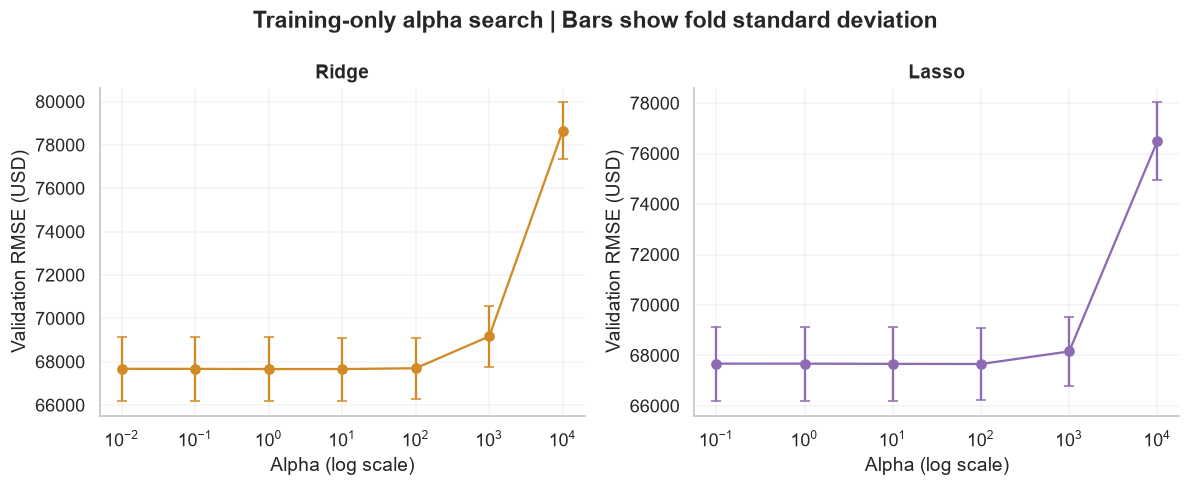

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ['Ridge','Lasso']):
    part = grid_results.loc[grid_results['Model'].eq(name)]
    ax.errorbar(part['Alpha'], part['CV RMSE'], yerr=part['CV RMSE std'],
                 color=MODEL_COLORS[name], marker='o', capsize=3)
    ax.set(xscale='log', xlabel='Alpha (log scale)', ylabel='Validation RMSE (USD)', title=name)
fig.suptitle('Training-only alpha search | Bars show fold standard deviation', weight='bold')
fig.tight_layout()
save_figure(fig, 'alpha_search.png')
plt.show()

## 12 · Held-Out Evaluation

Evaluate all three fixed models on identical test rows. RMSE and MAE are in dollars; lower is better. R² compares squared error with the test-target mean reference; higher is better. No tuning follows this evaluation.

In [12]:
predictions = {}
rows = []
for name, model in models.items():
    check_is_fitted(model.named_steps['model'])
    predicted = model.predict(X_test)
    assert np.isfinite(predicted).all()
    predictions[name] = predicted
    train_predicted = model.predict(X_train)
    rows.append({'Model':name, 'RMSE':np.sqrt(mean_squared_error(y_test,predicted)),
                 'MAE':mean_absolute_error(y_test,predicted), 'R2':r2_score(y_test,predicted),
                 'Train RMSE':np.sqrt(mean_squared_error(y_train,train_predicted)),
                 **cv_summary.loc[name].to_dict()})
comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv(RESULTS / 'model_comparison.csv')
display(comparison.round(3))
baseline_predictions = np.full(len(y_test), y_train.mean())
baseline_rmse = float(np.sqrt(mean_squared_error(y_test,baseline_predictions)))
display(Markdown(f'Training-mean baseline test RMSE: **${baseline_rmse:,.2f}**.'))
prediction_table = pd.DataFrame({'source_row':X_test.index,'actual':y_test.to_numpy(), **predictions})
prediction_table.to_csv(RESULTS / 'test_predictions.csv', index=False)

,RMSE,MAE,R2,Train RMSE,Alpha,CV RMSE,CV RMSE std
Model,,,,,,,
OLS,68845.002,49458.665,0.638,67366.069,NaN,67675.280,1467.328
Ridge,68897.954,49469.163,0.638,67382.721,10.0,67663.055,1456.130
Lasso,68937.051,49426.837,0.637,67410.322,100.0,67660.866,1439.109


Training-mean baseline test RMSE: **$114,485.64**.

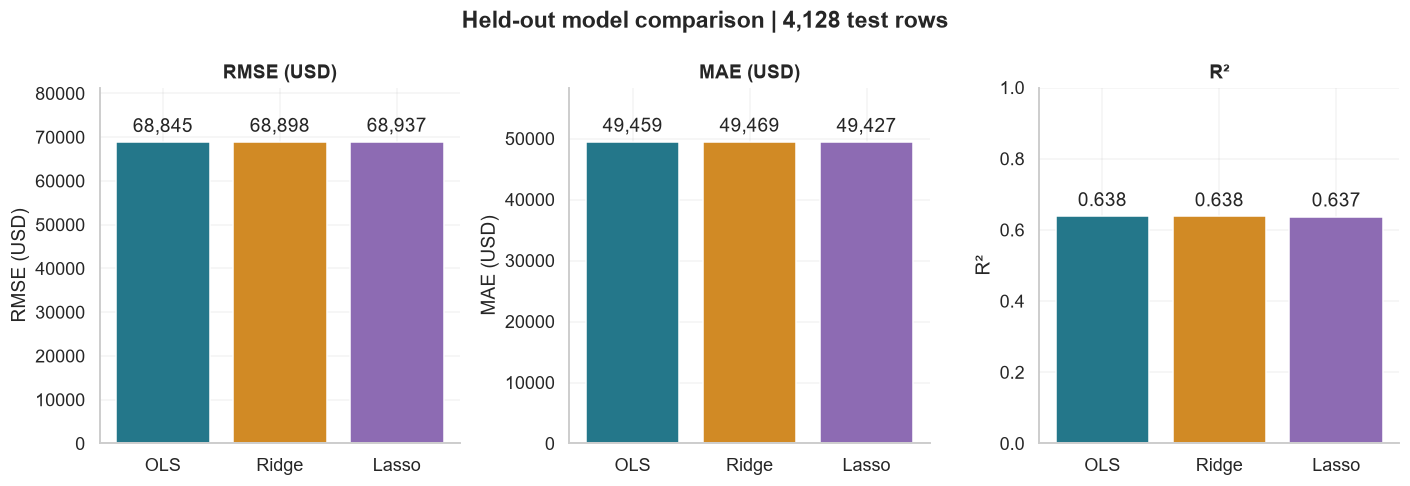

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, metric, label in zip(axes, ['RMSE','MAE','R2'], ['RMSE (USD)','MAE (USD)','R²']):
    bars = ax.bar(comparison.index, comparison[metric], color=[MODEL_COLORS[n] for n in comparison.index])
    ax.bar_label(bars, labels=[f'{v:,.0f}' if metric != 'R2' else f'{v:.3f}' for v in comparison[metric]], padding=4)
    ax.set(title=label, ylabel=label)
    ax.set_ylim(0, max(comparison[metric].max()*1.18, 1 if metric=='R2' else 0))
fig.suptitle('Held-out model comparison | 4,128 test rows', weight='bold')
fig.tight_layout()
save_figure(fig, 'model_comparison.png')
plt.show()

## 13 · Predicted vs Actual Values

A dashed identity line marks perfect predictions. All panels share the same limits and use every held-out row. Predictions are not clipped to the target range.

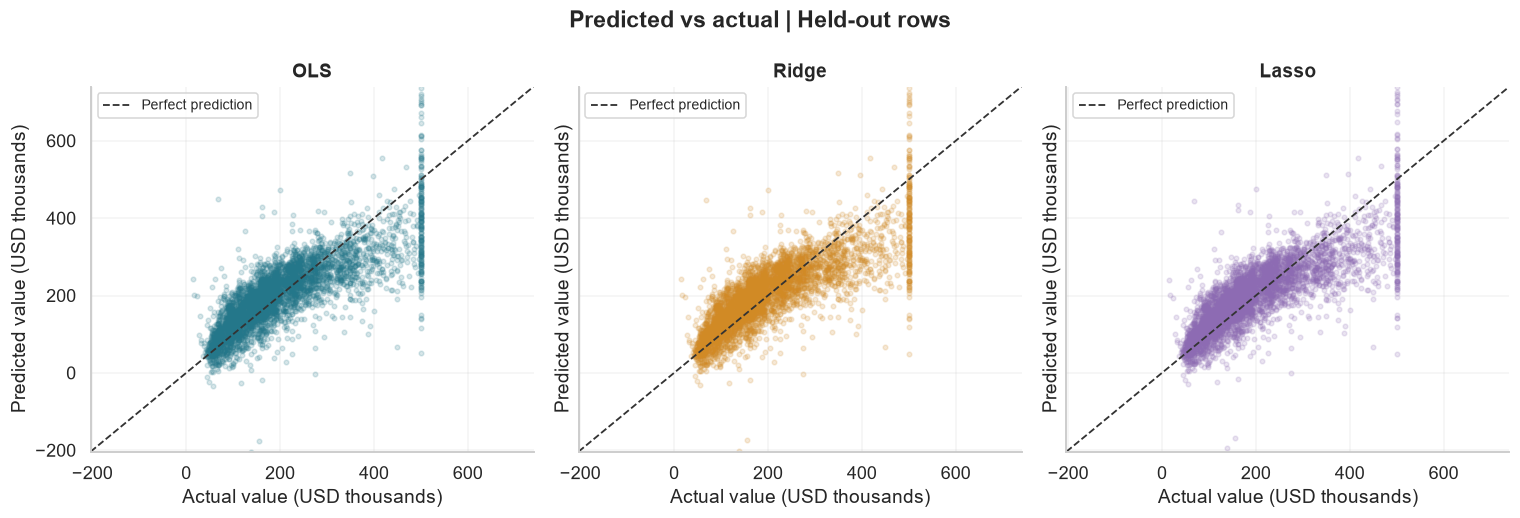

In [14]:
lower = min(0, min(v.min() for v in predictions.values()) / 1000)
upper = max(y_test.max(), max(v.max() for v in predictions.values())) / 1000
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
for ax, (name, predicted) in zip(axes, predictions.items()):
    ax.scatter(y_test / 1000, predicted / 1000, s=9, alpha=0.18, color=MODEL_COLORS[name], rasterized=True)
    ax.plot([lower,upper], [lower,upper], '--', color='#333333', linewidth=1.2, label='Perfect prediction')
    ax.set(title=name, xlabel='Actual value (USD thousands)', ylabel='Predicted value (USD thousands)',
           xlim=(lower,upper), ylim=(lower,upper))
    ax.legend(fontsize=9)
fig.suptitle('Predicted vs actual | Held-out rows', weight='bold')
fig.tight_layout()
save_figure(fig, 'predicted_vs_actual.png')
plt.show()

## 14 · Residual Analysis

Residual = actual − predicted. Positive values indicate underprediction; negative values indicate overprediction. Common bins and axes make model differences comparable.

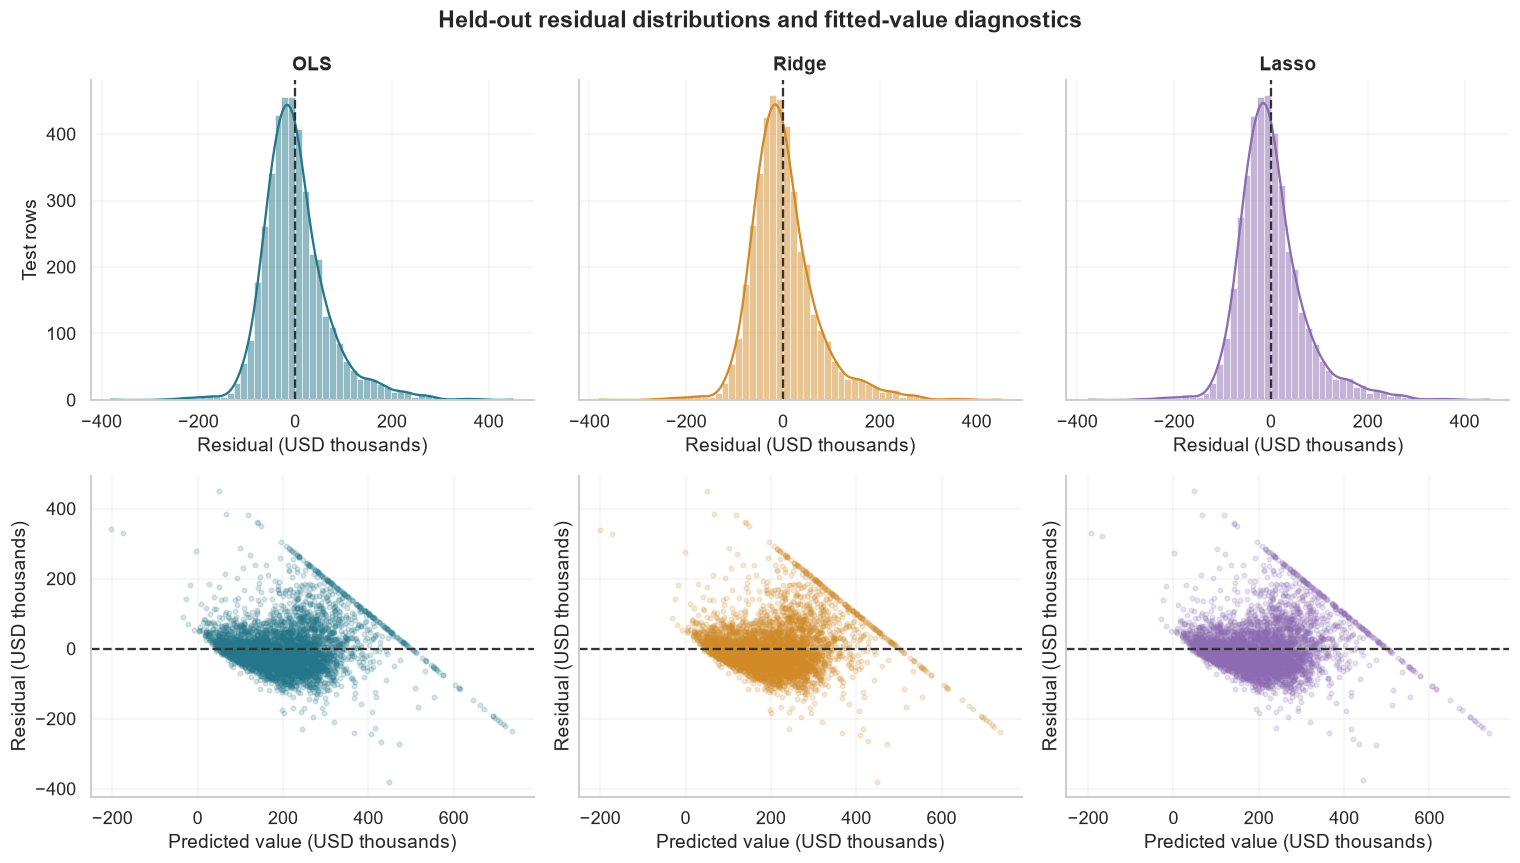

In [15]:
residuals = {name:y_test.to_numpy()-predicted for name,predicted in predictions.items()}
all_residuals = np.concatenate(list(residuals.values())) / 1000
bins = np.linspace(all_residuals.min(), all_residuals.max(), 60)
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey='row', sharex='row')
for column, (name, values) in enumerate(residuals.items()):
    sns.histplot(values / 1000, bins=bins, kde=True, color=MODEL_COLORS[name], ax=axes[0,column])
    axes[0,column].axvline(0, color='#333333', linestyle='--')
    axes[0,column].set(title=name, xlabel='Residual (USD thousands)', ylabel='Test rows')
    axes[1,column].scatter(predictions[name] / 1000, values / 1000, s=9, alpha=0.18, color=MODEL_COLORS[name])
    axes[1,column].axhline(0, color='#333333', linestyle='--')
    axes[1,column].set(xlabel='Predicted value (USD thousands)', ylabel='Residual (USD thousands)')
fig.suptitle('Held-out residual distributions and fitted-value diagnostics', weight='bold')
fig.tight_layout()
save_figure(fig, 'residual_analysis.png')
plt.show()

The residual plots show long tails and a non-random pattern rather than a uniform band around zero. The diagonal edge is consistent with the target endpoint: when actual value is fixed, residual decreases as prediction increases. These patterns limit the linear models; no post-test tuning is applied.

## 15 · Coefficients and Conditioning

Inspect the final training design matrix and coefficient patterns. Numeric features are standardized; one-hot indicators are unscaled, so coefficient magnitudes are not a universal feature-importance ranking. Regularization reduces sensitivity to correlated columns but does not prove causation.

Design rank: 18/18; condition number: 128.46


,L2 coefficient norm,Zero coefficients
OLS,189381.364,0
Ridge,140385.106,0
Lasso,131886.174,1


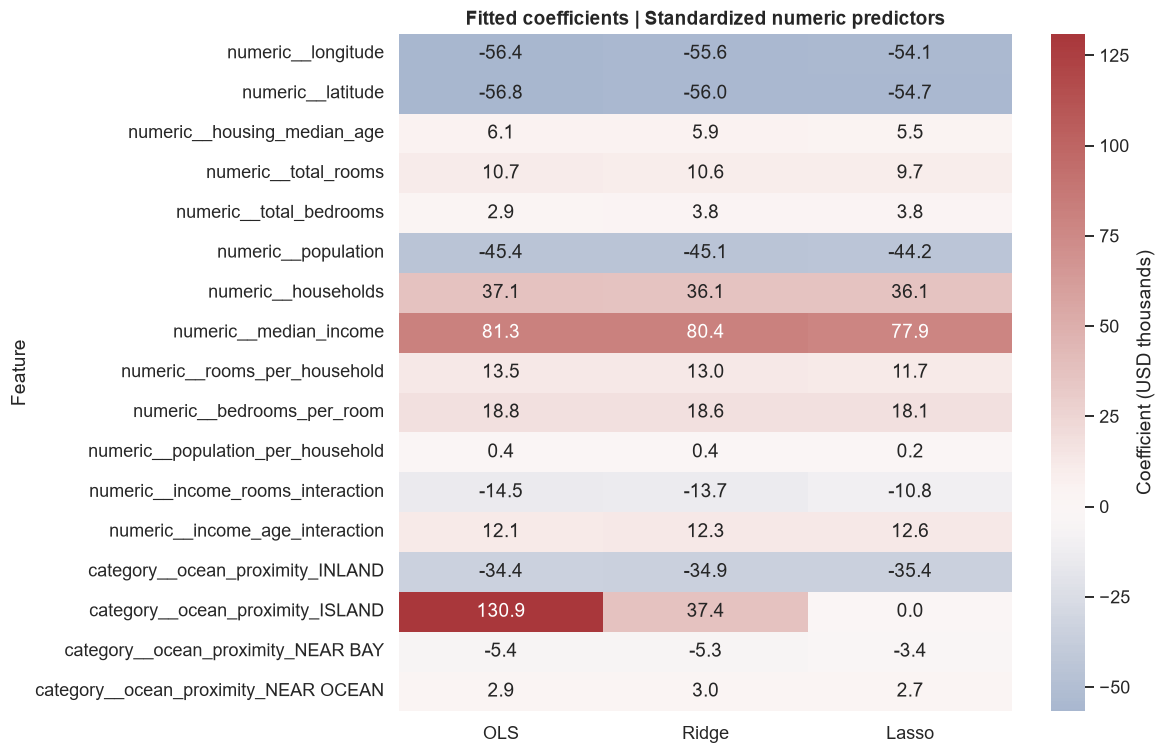

In [16]:
preprocessor = ols.named_steps['preprocess']
design = preprocessor.transform(engineer_features(X_train))
feature_names = preprocessor.get_feature_names_out()
design_with_intercept = np.column_stack([np.ones(len(design)),design])
condition_number = float(np.linalg.cond(design_with_intercept))
rank = int(np.linalg.matrix_rank(design_with_intercept))
print(f'Design rank: {rank}/{design_with_intercept.shape[1]}; condition number: {condition_number:.2f}')
coefficients = pd.DataFrame({name:model.named_steps['model'].coef_ for name,model in models.items()}, index=feature_names)
coefficients.index.name = 'Feature'
coefficients.to_csv(RESULTS / 'coefficients.csv')
display(pd.DataFrame({'L2 coefficient norm':[np.linalg.norm(coefficients[n]) for n in models],
                      'Zero coefficients':[int(np.isclose(coefficients[n],0,atol=1e-8).sum()) for n in models]}, index=list(models)))
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(coefficients / 1000, cmap='vlag', center=0, annot=True, fmt='.1f', ax=ax,
            cbar_kws={'label':'Coefficient (USD thousands)'})
ax.set_title('Fitted coefficients | Standardized numeric predictors')
save_figure(fig, 'coefficients.png')
plt.show()

## 16 · Largest Errors and Category Coverage

Review the ten largest absolute errors for the model selected by cross-validation. This is diagnostic reporting only. Small groups do not support reliable subgroup conclusions.

In [17]:
errors = X_test.copy()
errors.insert(0,'actual',y_test)
errors.insert(1,'predicted',predictions[selected_name])
errors['residual'] = residuals[selected_name]
errors['absolute_error'] = errors['residual'].abs()
largest_errors = errors.nlargest(10,'absolute_error')
largest_errors.index.name = 'source_row'
largest_errors.to_csv(RESULTS / 'largest_errors.csv')
display(largest_errors.round(2))
group_errors = errors.groupby('ocean_proximity').agg(test_rows=('actual','size'),MAE=('absolute_error','mean'))
display(group_errors.round(2))
print('Negative predictions by model:', {n:int((p<0).sum()) for n,p in predictions.items()})

,actual,predicted,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,residual,absolute_error
source_row,,,,,,,,,,,,,
6688,500001.0,48915.43,-118.08,34.15,28.0,238.0,58.0,142.0,31.0,0.50,INLAND,451085.57,451085.57
19542,450000.0,67004.28,-120.92,37.63,39.0,45.0,8.0,22.0,9.0,1.77,INLAND,382995.72,382995.72
10574,500001.0,118552.21,-117.70,33.72,6.0,211.0,51.0,125.0,44.0,1.97,<1H OCEAN,381448.79,381448.79
4548,67500.0,443810.72,-118.21,34.02,52.0,22.0,7.0,55.0,7.0,7.58,<1H OCEAN,-376310.72,376310.72
459,500001.0,140975.19,-122.25,37.87,52.0,609.0,236.0,1349.0,250.0,1.17,NEAR BAY,359025.81,359025.81
12069,500001.0,142958.38,-117.55,33.83,6.0,502.0,76.0,228.0,65.0,4.24,INLAND,357042.62,357042.62
12389,500001.0,149785.60,-116.43,33.75,24.0,2596.0,438.0,473.0,237.0,3.77,INLAND,350215.40,350215.40
13890,137500.0,-194074.24,-116.14,34.45,12.0,8796.0,1721.0,11139.0,1680.0,2.26,INLAND,331574.24,331574.24
9172,154600.0,-167810.05,-118.59,34.47,5.0,538.0,98.0,8733.0,105.0,4.24,INLAND,322410.05,322410.05


,test_rows,MAE
ocean_proximity,,
<1H OCEAN,1795,51324.74
INLAND,1324,36823.56
ISLAND,1,213724.34
NEAR BAY,436,66149.49
NEAR OCEAN,572,59609.75


Negative predictions by model: {'OLS': 8, 'Ridge': 8, 'Lasso': 7}


## 17 · Findings and Limitations

The following summary is generated from actual execution. The model choice remains the training-CV choice even if the held-out ordering differs.

In [18]:
selected = comparison.loc[selected_name]
observed_best = comparison['RMSE'].idxmin()
discussion = (
    f"Training CV selected **{selected_name}** (RMSE **${selected['CV RMSE']:,.2f}**). "
    f"Its held-out RMSE is **${selected['RMSE']:,.2f}**, MAE **${selected['MAE']:,.2f}** "
    f"and R² **{selected['R2']:.3f}**. "
    f"The lowest observed test RMSE belongs to **{observed_best}**; "
    "that test ordering is descriptive and is not used for further selection or tuning."
)
display(Markdown(discussion))
summary = {'selected_by_cv':selected_name,'lowest_test_rmse':observed_best,
           'train_rows':len(X_train),'test_rows':len(X_test),
           'source_sha256':source_sha256,'baseline_test_rmse':baseline_rmse,
           'design_condition_number':condition_number,'design_rank':rank}
(RESULTS / 'run_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

Training CV selected **Lasso** (RMSE **$67,660.87**). Its held-out RMSE is **$68,937.05**, MAE **$49,426.84** and R² **0.637**. The lowest observed test RMSE belongs to **OLS**; that test ordering is descriptive and is not used for further selection or tuning.

304

- Linear models may miss nonlinear location effects; interaction features only capture the relationships explicitly supplied.
- The target piles up at $500,001 in this benchmark. Errors near that endpoint reflect the recorded target, not uncensored market values.
- A random row split can place nearby areas in both partitions; it does not establish generalization to unseen regions or future years.
- Extreme area-level ratios and rare categories can make predictions unstable. They remain visible in the error analysis.
- CV standard deviation describes fold variation, not a confidence interval. Small differences do not establish universal model superiority.
- The CSV follows an upstream branch and requires Internet access. Its fingerprint is recorded for traceability.

## 18 · Verification

Recalculate metrics from saved predictions and verify fitted training-only preprocessing. No metric values are manually inserted.

In [19]:
saved_predictions = pd.read_csv(RESULTS / 'test_predictions.csv')
for name, model in models.items():
    predicted = saved_predictions[name].to_numpy()
    actual = saved_predictions['actual'].to_numpy()
    differences = actual-predicted
    manual = [np.sqrt(np.mean(differences**2)), np.mean(np.abs(differences)),
              1-np.sum(differences**2)/np.sum((actual-actual.mean())**2)]
    np.testing.assert_allclose(comparison.loc[name,['RMSE','MAE','R2']].to_numpy(dtype=float),manual)
    fitted_numeric = model.named_steps['preprocess'].named_transformers_['numeric']
    medians = engineer_features(X_train)[ALL_NUMERIC].median().to_numpy()
    np.testing.assert_allclose(fitted_numeric.named_steps['imputer'].statistics_,medians)
    assert fitted_numeric.named_steps['scaler'].n_samples_seen_ == len(X_train)
    assert np.isfinite(model.named_steps['preprocess'].transform(engineer_features(X_test))).all()
assert selected_name == cv_summary['CV RMSE'].idxmin()
for filename in ['training_distributions.png','correlation_heatmap.png','alpha_search.png',
                 'model_comparison.png','predicted_vs_actual.png','residual_analysis.png','coefficients.png']:
    assert (FIGURES/filename).stat().st_size > 1000
for filename in ['model_comparison.csv','alpha_search.csv','test_predictions.csv','coefficients.csv','largest_errors.csv','run_summary.json']:
    assert (RESULTS/filename).stat().st_size > 0
print('Verified: source, split, fitted preprocessing, model metrics, 7 figures and 6 results files.')

Verified: source, split, fitted preprocessing, model metrics, 7 figures and 6 results files.
